In [1]:
import os, glob, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})

V4 = os.path.abspath("../../wildfire-dataset")     # the dataset folder (sits next to this repository)
DS = V4 + "/dataset"                                       # built datasets
RAW = V4 + "/inputs_raw"                                   # raw downloads, exactly as they arrived
START = pd.Timestamp("2019-01-01")                         # day 0 of the cube; day t = START + t days

# 05. Terrain, people and roads

Three static layers: they do not change from day to day, so each cell has one fixed value.

| channel | source | why it might matter |
|---|---|---|
| `elevation`, `slope` | Copernicus DEM, 30 m, averaged to the cell | fires run uphill faster; high places are cooler |
| `population_density` | WorldPop 2020, 1 km | most fires are started by people |
| `distance_to_roads_km` | OpenStreetMap roads, January 2021 | roads bring people, and they also stop fires |

## 1. Elevation and slope: raw

18391 cells, one row each: {'first six states': 9561, 'newer states': 8830}


,cell_id,lon,lat,elevation,slope,source
0,81775,77.5,8.1,12.57,1.52,newer states
1,82773,77.3,8.2,37.29,2.75,newer states
2,82774,77.4,8.2,78.56,5.54,newer states
3,82775,77.5,8.2,79.71,6.20,newer states


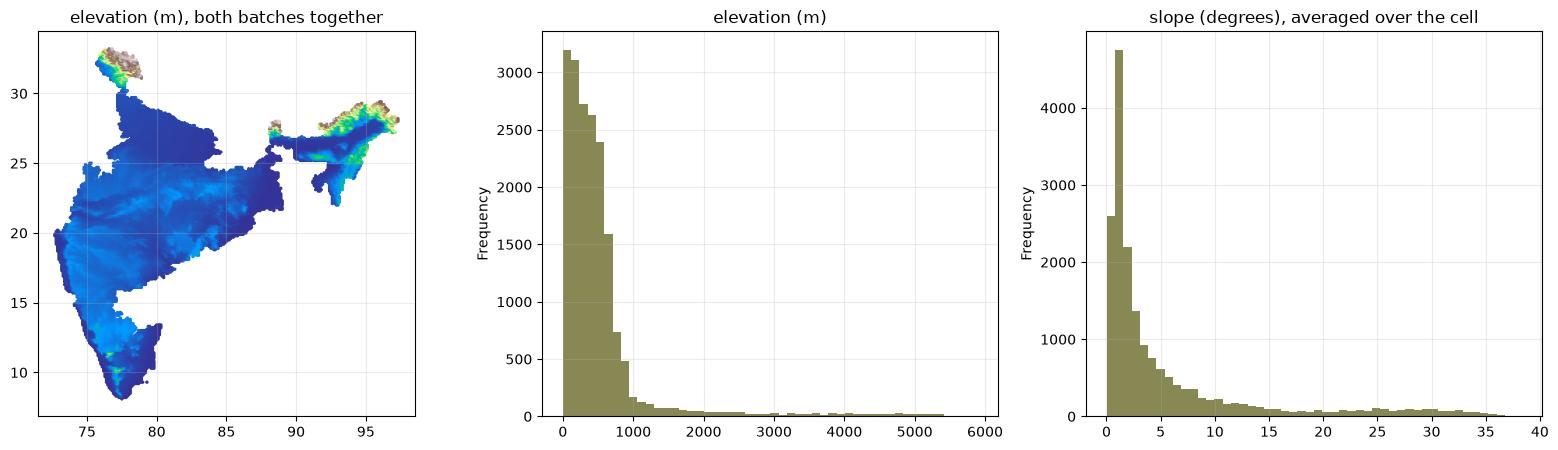

In [2]:
SOURCES = {"newer states": RAW + "/gee_new_states", "first six states": RAW + "/gee_six_states"}     # same format in both
dem = pd.concat(pd.read_csv(f).assign(source=k) for k, p in SOURCES.items() for f in sorted(glob.glob(p + "/dem/*.csv")))
print(len(dem), "cells, one row each:", dem.source.value_counts().to_dict())
display(dem.head(4).round(2))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
ax[0].scatter(dem.lon, dem.lat, c=dem.elevation, s=2, cmap="terrain"); ax[0].set_title("elevation (m), both batches together"); ax[0].set_aspect("equal")
dem.elevation.plot.hist(bins=50, ax=ax[1], color="#885"); ax[1].set_title("elevation (m)")
dem.slope.plot.hist(bins=50, ax=ax[2], color="#885"); ax[2].set_title("slope (degrees), averaged over the cell")
plt.tight_layout(); plt.show()

In [3]:
# do the raw numbers equal the cube, for ALL forest cells of both batches?
import sys; sys.path.insert(0, os.path.abspath("../src"))
from wildfire_forecast import data
cells = pd.read_parquet(f"{DS}/forest_all/cells.parquet")
ds = data.load_train(); names = [str(n) for n in np.load(f"{DS}/scaler_forest_A_train.npz", allow_pickle=True)["names"]]
one_day = np.asarray(ds.cube[1000])                       # elevation, slope, population, roads do not change over time, so any day will do
both = cells.merge(dem, on="cell_id")
for ch in ("elevation", "slope"):
    print(f"{ch:10s} {len(both)} forest cells compared, largest difference between the raw file and the cube: {float(np.abs(one_day[both.cell_idx.values, names.index(ch)] - both[ch].values).max()):.6f}")

elevation  6320 forest cells compared, largest difference between the raw file and the cube: 0.000214
slope      6320 forest cells compared, largest difference between the raw file and the cube: 0.000002


**Which cells are covered?** The raw tables here hold the first six states and the newer states: 6,320 of our 7,148 forest cells. The other 828 cells (Andhra Pradesh and Uttarakhand, sets D1 and D2) were built earlier from a separate export that is not in these tables, so they are not part of this check. Their values are in the cube like all the others.

`slope` is computed at 30 m and then averaged over the cell. The average hides steep local slopes: a cell with a flat plain and a cliff gets a small number.

## 2. Population: raw GeoTIFF

WorldPop 2020: 3508 x 3451 pixels, 0.92 km per pixel, EPSG:4326  one value = people in the pixel


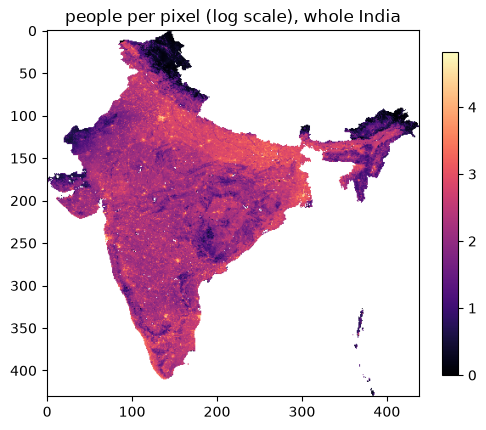

In [4]:
import rasterio
with rasterio.open(f"{RAW}/worldpop/ind_ppp_2020_1km_Aggregated.tif") as r:
    print("WorldPop 2020:", r.width, "x", r.height, "pixels,", round(r.res[0] * 111, 2), "km per pixel,", r.crs, " one value = people in the pixel")
    pop = r.read(1, out_shape=(r.height // 8, r.width // 8)); pop = np.where(pop < 0, np.nan, pop)
plt.figure(figsize=(6, 6)); plt.imshow(np.log10(pop + 1), cmap="magma"); plt.title("people per pixel (log scale), whole India"); plt.grid(False); plt.colorbar(shrink=0.7); plt.show()

For each 0.1 degree cell we add up the people in the 1 km pixels whose centre falls in the cell and divide by the cell area: **people per km2**.
The first six states were calculated in the first build and the newer states with the same code later; the new code was tested against the old one on 400 cells and gave the same numbers.

In [5]:
st = cells[["cell_id", "state", "set"]].assign(population_density=one_day[:, names.index("population_density")], distance_to_roads_km=one_day[:, names.index("distance_to_roads_km")])
print(len(st), "forest cells, all states together (values as stored in the cube)")
st.head(4).round(2)

7148 forest cells, all states together (values as stored in the cube)


,cell_id,state,set,population_density,distance_to_roads_km
0,157741,MH,six,52.160000,0.39
1,158740,MH,six,48.950001,2.81
2,158741,MH,six,90.320000,0.30
3,158742,MH,six,117.290001,0.36


## 3. Roads: raw OpenStreetMap

In [6]:
pbf = f"{RAW}/osm/india-210101.osm.pbf"
print("raw file:", os.path.basename(pbf), round(os.path.getsize(pbf) / 1e9, 2), "GB   (a binary extract of all of India, snapshot of 1 January 2021)")

raw file: india-210101.osm.pbf 0.84 GB   (a binary extract of all of India, snapshot of 1 January 2021)


The whole file is too big to look at, so we **cut out one small area** with the `osmium` tool: the Similipal forest in Odisha (a box of 0.9 x 0.9 degree). This takes a few seconds.

In [7]:
import subprocess, shutil
CACHE = os.path.abspath("_cache"); os.makedirs(CACHE, exist_ok=True)
BOX = (85.9, 21.3, 86.8, 22.2)                                    # lon_min, lat_min, lon_max, lat_max
roads_file = CACHE + "/similipal_roads.geojsonseq"
if not os.path.exists(roads_file):                                # only the first run does the cutting
    osmium = shutil.which("osmium") or "/opt/homebrew/bin/osmium"
    box = ",".join(map(str, BOX))
    subprocess.run([osmium, "extract", "-b", box, "--strategy", "complete_ways", "-o", CACHE + "/_box.osm.pbf", "--overwrite", pbf], check=True)
    subprocess.run([osmium, "tags-filter", CACHE + "/_box.osm.pbf", "w/highway", "-o", CACHE + "/_hw.osm.pbf", "--overwrite"], check=True)
    subprocess.run([osmium, "export", CACHE + "/_hw.osm.pbf", "-f", "geojsonseq", "-o", roads_file, "--overwrite"], check=True)

# read the lines: every road is a list of (lon, lat) points plus a "highway" tag that says what kind of road it is
roads = []
for line in open(roads_file):
    line = line.strip("\x1e\n")
    if not line: continue
    f = json.loads(line)
    if f["geometry"]["type"] == "LineString" and "highway" in f["properties"]:
        roads.append((f["properties"]["highway"], np.array(f["geometry"]["coordinates"])))
print(len(roads), "road lines in the box")
pd.Series([k for k, _ in roads]).value_counts().to_frame("lines")

336 road lines in the box


,lines
tertiary,80
trunk,69
unclassified,68
residential,56
primary,51
secondary,10
track,1
steps,1


Each road line has a type (`highway = ...`). The first five are the big roads; `residential` and `unclassified` are village and small roads; `track` is a dirt or forest track.
We keep these types: motorway, trunk, primary, secondary, tertiary (and their `_link` ramps), unclassified, residential, track.
Footpaths, steps and service roads are not counted.

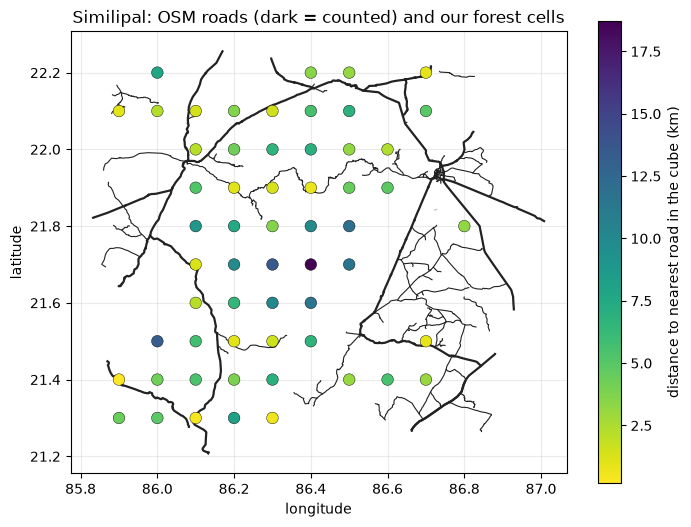

58 forest cells in this box


In [8]:
KEEP = {"motorway", "trunk", "primary", "secondary", "tertiary", "unclassified", "residential", "track"}
KEEP |= {k + "_link" for k in ("motorway", "trunk", "primary", "secondary", "tertiary")}

cells = pd.read_parquet(f"{DS}/forest_all/cells.parquet")
inbox = cells[(cells.lon.between(BOX[0], BOX[2])) & (cells.lat.between(BOX[1], BOX[3]))]
import sys; sys.path.insert(0, os.path.abspath("../src"))
from wildfire_forecast import data
ds = data.load_train(); names = [str(n) for n in np.load(f"{DS}/scaler_forest_A_train.npz", allow_pickle=True)["names"]]
stored = np.asarray(ds.cube[1000][:, names.index("distance_to_roads_km")])      # static channel: any day gives the same value
inbox = inbox.assign(stored_km=stored[inbox.cell_idx.values])

fig, ax = plt.subplots(figsize=(8, 7.5))
for kind, xy in roads:
    ax.plot(xy[:, 0], xy[:, 1], color="#222" if kind in KEEP else "#bbb", lw=1.6 if kind in ("trunk", "primary") else 0.8)
sc = ax.scatter(inbox.lon, inbox.lat, c=inbox.stored_km, s=70, cmap="viridis_r", edgecolor="k", linewidth=0.3, zorder=3)
plt.colorbar(sc, label="distance to nearest road in the cube (km)", shrink=0.8); ax.set_aspect("equal")
ax.set_title("Similipal: OSM roads (dark = counted) and our forest cells"); ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); plt.show()
print(len(inbox), "forest cells in this box")

The dots are the cell centres. The colour is the number we gave the model: kilometres to the nearest counted road.
Notice how few roads OSM has inside the forest itself. The cells far from any mapped road get large values, and **a real forest track missing from OSM looks the same as no track at all.**

## Doing the calculation by hand

For one cell: take points along every counted road at most 0.001 degree apart, find the nearest one, and measure the great-circle distance. Does it match the cube?

In [9]:
from scipy.spatial import cKDTree

pts = []                                                    # points along the counted roads, at most 0.001 degree apart
for kind, xy in roads:
    if kind not in KEEP: continue
    for (x0, y0), (x1, y1) in zip(xy[:-1], xy[1:]):
        n = max(int(np.ceil(max(abs(x1 - x0), abs(y1 - y0)) / 0.001)), 1)
        pts += [(x0 + (x1 - x0) * k / n, y0 + (y1 - y0) * k / n) for k in range(n + 1)]
pts = np.array(pts); print(len(pts), "points along the roads")

def xyz(lon, lat):                                          # position on a unit sphere, so the nearest point in 3D is the nearest on Earth
    lo, la = np.radians(lon), np.radians(lat); return np.c_[np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)]
chord, _ = cKDTree(xyz(pts[:, 0], pts[:, 1])).query(xyz(inbox.lon.values, inbox.lat.values))
mine = 2 * 6371.0088 * np.arcsin(chord / 2)                 # chord length to great-circle km
inbox = inbox.assign(my_km=mine)

# a cell close to the box edge may have its nearest road outside the box: leave those out of the comparison
edge = np.minimum.reduce([inbox.lon - BOX[0], BOX[2] - inbox.lon, inbox.lat - BOX[1], BOX[3] - inbox.lat]) * 111
fair = inbox[inbox.stored_km < edge]
diff = (fair.my_km - fair.stored_km).abs()
print(f"{len(fair)} cells compared.  largest difference {diff.max():.3f} km,  mean difference {diff.mean():.4f} km")
fair[["cell_id", "state", "stored_km", "my_km"]].head(6).round(3)

33415 points along the roads
45 cells compared.  largest difference 0.000 km,  mean difference 0.0001 km


,cell_id,state,stored_km,my_km
2150,214860,OD,4.186,4.186
2151,214861,OD,5.438,5.438
2152,214862,OD,3.828,3.828
2153,214863,OD,6.933,6.933
2154,214865,OD,3.110,3.110
2155,214866,OD,5.584,5.584


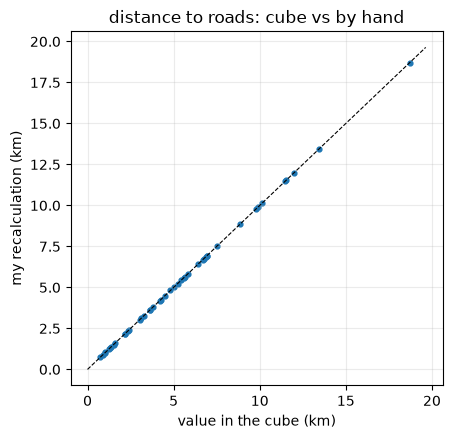

In [10]:
plt.figure(figsize=(4.8, 4.6)); plt.scatter(fair.stored_km, fair.my_km, s=12); lim = [0, max(fair.stored_km.max(), fair.my_km.max()) * 1.05]
plt.plot(lim, lim, "k--", lw=0.8); plt.xlabel("value in the cube (km)"); plt.ylabel("my recalculation (km)"); plt.title("distance to roads: cube vs by hand"); plt.show()

The two agree, so the road channel is what we say it is: distance to the nearest counted OSM road, as it was on 1 January 2021.

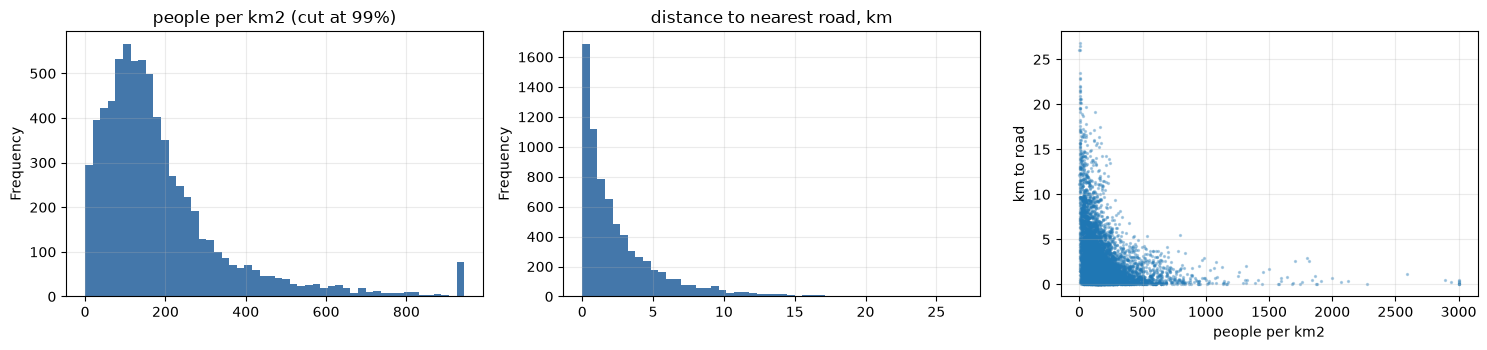

cells without a population value: 0


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
st.population_density.clip(upper=st.population_density.quantile(0.99)).plot.hist(bins=50, ax=ax[0], color="#47a"); ax[0].set_title("people per km2 (cut at 99%)")
st.distance_to_roads_km.plot.hist(bins=50, ax=ax[1], color="#47a"); ax[1].set_title("distance to nearest road, km")
ax[2].scatter(st.population_density.clip(upper=3000), st.distance_to_roads_km, s=2, alpha=0.3); ax[2].set_xlabel("people per km2"); ax[2].set_ylabel("km to road")
plt.tight_layout(); plt.show()
print("cells without a population value:", int(st.population_density.isna().sum()))

## 4. What is missing or weak here

- **Static in time.** Roads are from January 2021 and population from 2019 and 2020. A road built in 2024 does not exist for us.
- **OSM is incomplete in some states.** Road density between states differs a lot, partly because of mapping effort, not real roads (a warning noted in the v4 audit).
- **Roads inside forests** (forest tracks, fire lines) are poorly mapped, and those are the ones that matter most. The Similipal map above shows it: almost no tracks inside the forest.
- **Population is a count of people living nearby**, not of people visiting or burning crop waste.
- **Averaging over 11 km** hides local effects like a village next to a forest edge.
- Previous tests showed population density and slope have an unstable sign between training and validation years, so we should not read much into them.